# Combined corpora — §6 device productivity

Both-corpora versions of `productivity.ipynb` / `arxiv/productivity.ipynb`:

- **§6.1 Paper support per device model** — the two-panel bar figure (volume and
  age-normalised rate), with two bars per model, one per corpus.
- **§6.1b Paper support over a device's life** — papers per year against years
  since release, as two columns of subplots, one per corpus.

Both figures read the same paper x model credit units, so the expensive part (the
mentions scan + `canonicalize_column`, per corpus) is done **once** in the load cell
below and shared. Series for §6.1b come from `accelscan.webexport.device_life_series`,
the same function the single-corpus notebooks call.

> Descriptive attribution, not causal: a paper crediting a chip is not evidence the
> chip caused the result. Each supporting paper is counted once per model it names,
> so per-model counts sum to more than the number of papers — the intended
> semantics, not double counting.

**Cross-corpus levels.** Absolute counts are not comparable across corpora
(different corpus sizes and ingestion), so read the *shape* across models rather
than the gap between a row's two bars. The §6.1 rate panel is closer to comparable,
since it divides by the same observable window.

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from accelscan import webexport as we
from accelscan.normalize import canonicalize_column
from accelscan.paths import analytic_base, get_corpus, s3_uri
from accelscan.plotting import setup_figures
from accelscan.registry import load_registry
from accelscan.s3 import mentions_glob, storage_options

# integer year ticks + every figure exported to output/analysis/combined/productivity/
setup_figures('combined/productivity')

## Knobs

In [13]:
MODEL_TAG, PROMPT_VERSION = 'qwen3-14b', 'p1'
YEAR_MIN, YEAR_MAX = 2010, 2025
USED_ONLY = True            # restrict to used-in-this-work mentions
MIN_PAPERS_MODEL = 100      # eligibility bar, same as the single-corpus notebooks
TOP_N = 20                  # models per panel in 6.1, same as the single-corpus 6.1
TOP_N_CHANGE = 12           # models per panel in 6.1b, same as the single-corpus 6.1b

CORPUS_LABEL = {'s2orc': 'S2ORC', 'arxiv': 'arXiv'}
# 6.1 (bars): color carries the CORPUS -- S2ORC blue and solid, arXiv vermillion
# and hatched/translucent, the same corpus encoding as the other combined
# notebooks. The volume/rate distinction is carried by the panels themselves.
CORPUS_STYLE = {'s2orc': dict(color='#0072B2', alpha=1.0, hatch=None),
                'arxiv': dict(color='#D55E00', alpha=0.55, hatch='//')}
# 6.1b (lines): color carries the MODEL instead (the panels carry the corpus), so
# this is the per-model palette.
PAL = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9', '#999999',
       '#000000', '#984EA3', '#44AA99']
reg = load_registry(); so = storage_options()

## Load paper x model observations, both corpora

One load for both figures. `pm` is the paper x model credit table (one row per
(paper, model)); `elig` is its per-model rollup with the observable-life exposure
and rate, over the `MIN_PAPERS_MODEL` eligibility bar. Both are built exactly as
the single-corpus §6.1 `pm`/`sup`/`elig` cells build them, so these figures match
those rather than being a second construction.

In [14]:
# registry model metadata is corpus-independent, so it is built once
meta = pl.DataFrame(
    [{'canonical_model': x.id, 'display': x.display, 'manufacturer_reg': x.manufacturer,
      'segment': x.segment, 'architecture': x.architecture,
      'release_year': int(x.release[:4]) if x.release else None,
      'release_ym': x.release, 'fp32_gflops': x.fp32_gflops}
     for x in reg.models.values() if x.kind == 'model'],
    schema={'canonical_model': pl.Utf8, 'display': pl.Utf8, 'manufacturer_reg': pl.Utf8,
            'segment': pl.Utf8, 'architecture': pl.Utf8, 'release_year': pl.Int32,
            'release_ym': pl.Utf8, 'fp32_gflops': pl.Float64})

def load_support(corpus_name):
    """(pm, elig) for one corpus."""
    c = get_corpus(corpus_name); key = c.key
    base = s3_uri(analytic_base(c, reg.version, PROMPT_VERSION, MODEL_TAG))
    den = (pl.read_parquet(f'{base}/denominator.parquet', storage_options=so)
           .select(key, 'year'))
    m = (pl.scan_parquet(mentions_glob(MODEL_TAG, PROMPT_VERSION, corpus=c),
                         storage_options=so)
         .filter(pl.col('status') == 'ok')
         .select(key, 'model_normalized', 'manufacturer', 'usage_context')
         .collect())
    if USED_ONLY:
        m = m.filter(pl.col('usage_context') == 'used-in-this-work')
    m = canonicalize_column(m, reg).filter(pl.col('canonical_kind') == 'model')

    # one row per (paper, model): a paper supports every model it reports
    pm = (m.select(key, 'canonical_model').unique()
          .join(den, on=key, how='inner')
          .filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX))
          .join(meta, on='canonical_model', how='left'))
    sup = (pm.group_by('canonical_model', 'display', 'release_year', 'segment',
                       'architecture')
           .agg(papers=pl.len())
           .sort('papers', descending=True))
    # Observable lifetime: release -> end of window, clipped to the window's start
    # so pre-YEAR_MIN chips are not credited with years the corpus does not cover.
    # An unknown release date stays null rather than inheriting YEAR_MIN and
    # getting a full-window exposure (and so an invented rate).
    sup = sup.with_columns(
        exposure_years=pl.when(pl.col('release_year').is_not_null())
        .then((YEAR_MAX - pl.max_horizontal('release_year', pl.lit(YEAR_MIN)) + 1)
              .clip(1, None))
        .otherwise(None).cast(pl.Int32))
    sup = sup.with_columns(papers_per_year=pl.col('papers') / pl.col('exposure_years'))
    return pm, sup.filter(pl.col('papers') >= MIN_PAPERS_MODEL)

corpora = list(CORPUS_LABEL)   # fixes bar/panel/legend order throughout
pm_by_corpus, elig_by_corpus = {}, {}
for name in corpora:
    pm_by_corpus[name], elig_by_corpus[name] = load_support(name)
    print(f'{CORPUS_LABEL[name]}: {pm_by_corpus[name].height:,} paper-model rows | '
          f'{elig_by_corpus[name].height} models over the '
          f'>={MIN_PAPERS_MODEL}-paper bar')

S2ORC: 233,526 paper-model rows | 114 models over the >=100-paper bar
arXiv: 182,226 paper-model rows | 93 models over the >=100-paper bar


## 6.1 Paper support per device model

Same structure as the single-corpus §6.1 -- two horizontal-bar panels, two bars per
model (S2ORC solid, arXiv hatched):

- **Left — volume:** total papers supported. Structurally biased toward chips that
  have been available longer.
- **Right — rate:** papers supported per year of observable life, i.e. total support
  divided by `YEAR_MAX - max(release_year, YEAR_MIN) + 1`. This is what makes a 2023
  part comparable to a 2014 one.

**Ranking.** The panels are ranked *independently* (as in the single-corpus figure),
but each now ranks by the **sum across both corpora** of its own metric, so neither
corpus sets the order. A model eligible in only one corpus keeps its row and shows a
single bar rather than being dropped.

Exposure is truncated on both sides, so the newest parts' rates rest on one or two
years and are the least stable. Models with no registry release date are excluded
from the rate panel only.

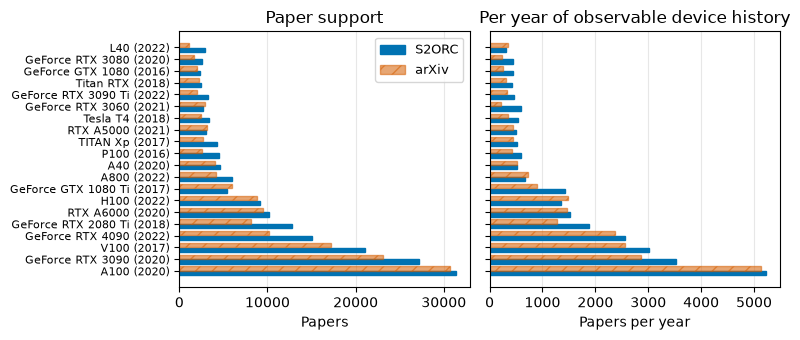

--- ranked by summed volume ---
shape: (20, 4)
┌────────────────────────────┬──────────────┬───────┬───────┐
│ display                    ┆ release_year ┆ S2ORC ┆ arXiv │
│ ---                        ┆ ---          ┆ ---   ┆ ---   │
│ str                        ┆ i32          ┆ u32   ┆ u32   │
╞════════════════════════════╪══════════════╪═══════╪═══════╡
│ NVIDIA A100                ┆ 2020         ┆ 31377 ┆ 30739 │
│ NVIDIA V100                ┆ 2017         ┆ 27190 ┆ 23087 │
│ NVIDIA GeForce RTX 3090    ┆ 2020         ┆ 21118 ┆ 17153 │
│ NVIDIA GeForce RTX 2080 Ti ┆ 2018         ┆ 15028 ┆ 10158 │
│ NVIDIA GeForce GTX 1080 Ti ┆ 2017         ┆ 12826 ┆ 8113  │
│ NVIDIA GeForce RTX 4090    ┆ 2022         ┆ 10222 ┆ 9477  │
│ NVIDIA RTX A6000           ┆ 2020         ┆ 9175  ┆ 8800  │
│ NVIDIA H100                ┆ 2022         ┆ 5411  ┆ 5946  │
│ NVIDIA P100                ┆ 2016         ┆ 5992  ┆ 4143  │
│ NVIDIA TITAN Xp            ┆ 2017         ┆ 4646  ┆ 3990  │
│ NVIDIA GeForce GTX 10

In [15]:
def combined_panel_frame(col: str, require_release: bool) -> pl.DataFrame:
    """One row per model with a `<corpus>` column per corpus, ranked by the SUM of
    `col` across corpora (so neither corpus alone sets the order), top TOP_N."""
    frames = []
    for name in corpora:
        d = elig_by_corpus[name]
        if require_release:
            d = d.filter(pl.col('release_year').is_not_null())
        frames.append(d.select('canonical_model', 'display', 'release_year',
                               pl.col(col).alias(name)))
    out = frames[0]
    for f in frames[1:]:
        out = out.join(f, on=['canonical_model', 'display', 'release_year'],
                       how='full', coalesce=True)
    return (out.with_columns(_total=pl.sum_horizontal([pl.col(n).fill_null(0)
                                                       for n in corpora]))
            .sort('_total', descending=True).head(TOP_N))

def grouped_barh(ax, d, xlabel, title):
    ys = np.arange(d.height)
    bar_h = 0.8 / len(corpora)
    for j, name in enumerate(corpora):
        vals = [v if v is not None else 0.0 for v in d[name]]
        offs = ys + (j - (len(corpora) - 1) / 2) * bar_h
        st = CORPUS_STYLE[name]
        ax.barh(offs, vals, bar_h * 0.9, color=st['color'], alpha=st['alpha'],
                hatch=st['hatch'], edgecolor=st['color'], label=CORPUS_LABEL[name])
    ax.set_yticks(ys)
    ax.set_yticklabels([f"{s.replace('NVIDIA ', '')} ({r})" for s, r in
                        zip(d['display'], d['release_year'])], fontsize=8)
    ax.invert_yaxis(); ax.set(xlabel=xlabel, title=title)
    ax.grid(alpha=0.3, axis='x'); ax.set_axisbelow(True)

vol = combined_panel_frame('papers', require_release=False)
rate = combined_panel_frame('papers_per_year', require_release=True)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
grouped_barh(axes[0], vol, 'Papers', 'Paper support')
grouped_barh(axes[1], rate, 'Papers per year',
            'Per year of observable device history')
axes[0].legend(fontsize=9, loc='upper right')   # both panels share the encoding

plt.tight_layout(); plt.show()

with pl.Config(tbl_rows=TOP_N, fmt_str_lengths=40):
    for label, d in (('volume', vol), ('rate', rate)):
        print(f'--- ranked by summed {label} ---')
        print(d.select('display', 'release_year',
                       *[pl.col(n).round(2).alias(CORPUS_LABEL[n]) for n in corpora]))

## 6.1b Paper support over a device's life

Where §6.1 gives each chip a single number, this shows the shape of its support over
time: papers supported per year on a log axis, plotted against **years since
release** so the lifecycles align -- a 2014 chip and a 2023 chip become directly
comparable instead of sitting in different parts of a calendar axis. Two columns of
subplots, one per corpus, on shared axes, so a vertical position means the same
number of papers in both.

Log scale because support spans orders of magnitude, and because on a log axis equal
*slopes* mean equal *growth rates*: ramp-up and decay phases can be compared between
chips even when their levels differ 100-fold. Years with zero supporting papers are
absent rather than plotted at zero, which a log axis cannot show.

**One shared legend, and what it costs.** Each corpus has its own top-`TOP_N_CHANGE`
models by paper support, and those two sets are not identical. Rather than draw two
legends against two different color assignments, this figure fixes **one color +
marker per model over the union of both sets** (ordered by release year), so a chip
looks the same in both panels and one legend serves the whole figure. Read it with
care: a model in the legend may be absent from one panel because it is not in that
corpus's top `TOP_N_CHANGE`, not because it supported no papers there.

Line style carries the era split (dashed/translucent before the union's median
release year, solid after), also computed once over the union so the split is
identical in both panels -- so "do newer chips ramp faster and fall off sooner?" is
a comparison of dashed against solid, within and across panels.

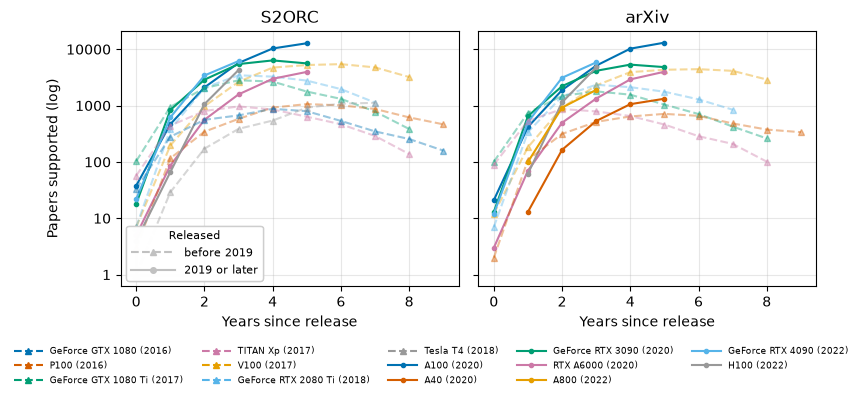

--- S2ORC ---
shape: (12, 6)
┌───────────────────┬──────────────┬─────────────┬──────────────────┬─────────────┬────────────────┐
│ display           ┆ release_year ┆ peak_papers ┆ peak_since_relea ┆ last_papers ┆ years_observed │
│ ---               ┆ ---          ┆ ---         ┆ se               ┆ ---         ┆ ---            │
│ str               ┆ i32          ┆ u32         ┆ ---              ┆ u32         ┆ u32            │
│                   ┆              ┆             ┆ i64              ┆             ┆                │
╞═══════════════════╪══════════════╪═════════════╪══════════════════╪═════════════╪════════════════╡
│ NVIDIA GeForce    ┆ 2016         ┆ 875         ┆ 4                ┆ 159         ┆ 10             │
│ GTX 1080          ┆              ┆             ┆                  ┆             ┆                │
│ NVIDIA P100       ┆ 2016         ┆ 1062        ┆ 5                ┆ 465         ┆ 10             │
│ NVIDIA GeForce    ┆ 2017         ┆ 2809        ┆ 3          

In [16]:
top_by_corpus = {name: elig.sort('papers', descending=True).head(TOP_N_CHANGE)
                 for name, elig in elig_by_corpus.items()}

# One color/marker/style per model over the UNION of both corpora's top-N, so a
# chip is identifiable across panels and a single legend serves both. Ordered by
# release year; the era split is the union's median release year, computed once.
union = (pl.concat([t.select('canonical_model', 'display', 'release_year')
                    for t in top_by_corpus.values()])
         .unique(subset='canonical_model')
         .filter(pl.col('release_year').is_not_null())
         .sort('release_year', 'display'))
split = union['release_year'].median()

style_of, seen = {}, {True: 0, False: 0}
for r in union.iter_rows(named=True):
    early = r['release_year'] < split
    idx = seen[early]; seen[early] += 1
    # marker carries the era too, so the two groups separate even where a dash
    # pattern is hard to see at legend scale
    style_of[r['canonical_model']] = dict(
        color=PAL[idx % len(PAL)], marker='^' if early else 'o',
        ms=4 if early else 3, ls='--' if early else '-',
        alpha=0.4 if early else 1.0,
        label=f"{r['display'].replace('NVIDIA ', '')} ({r['release_year']})")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
ts_by_corpus = {}
for ax, name in zip(axes, corpora):
    ts = we.device_life_series(pm_by_corpus[name], top_by_corpus[name])
    ts_by_corpus[name] = ts
    for cm in top_by_corpus[name]['canonical_model']:
        s = ts.filter(pl.col('canonical_model') == cm).sort('year')
        if s.height < 2 or cm not in style_of:
            continue
        ax.plot(s['since_release'], s['papers'], **style_of[cm])
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:g}')
    ax.set(xlabel='Years since release', title=CORPUS_LABEL[name])
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Papers supported (log)')

# Two legends. The era-encoding one sits inside the first panel (it explains the
# styles, whose dash patterns are unreadable at per-model legend scale); the
# per-model legend is shared, below both panels.
era = [plt.Line2D([], [], color='#C1C1C1', ls='--', marker='^', ms=5,
                  label=f'before {int(split)}'),
       plt.Line2D([], [], color='#C1C1C1', ls='-', marker='o', ms=4,
                  label=f'{int(split)} or later')]
axes[0].add_artist(axes[0].legend(handles=era, fontsize=8, loc='lower left',
                                 handlelength=4, title='Released',
                                 title_fontsize=8, framealpha=0.9))
model_handles = [plt.Line2D([], [], **{k: v for k, v in st.items() if k != 'alpha'})
                 for st in style_of.values()]
fig.legend(handles=model_handles, fontsize=6.5, ncol=5, loc='upper center',
          bbox_to_anchor=(0.5, 0.02), frameon=False, handlelength=3.2)

plt.tight_layout(); plt.show()

for name, ts in ts_by_corpus.items():
    print(f'--- {CORPUS_LABEL[name]} ---')
    with pl.Config(tbl_rows=30, fmt_str_lengths=34):
        print(ts.group_by('display', 'release_year')
              .agg(peak_papers=pl.col('papers').max(),
                   peak_since_release=pl.col('since_release')
                   .filter(pl.col('papers') == pl.col('papers').max()).first(),
                   last_papers=pl.col('papers')
                   .filter(pl.col('year') == pl.col('year').max()).first(),
                   years_observed=pl.len())
              .sort('release_year', 'display'))